# Crime Incident Analysis
## Phase 3: Visualization Selection and Graphical Representation

**Final Google Colab notebook**

Upload using **File → Upload notebook**. Saved tables and static plots are already included. To enable the interactive dashboard, select **Runtime → Run all** and upload the original CSV when requested. No Phase 1 or Phase 2 notebook is required.

Outputs were computed from the supplied CSV in Python outside a live Colab session. The dashboard is an HTML/JavaScript output: rerun its cell if the notebook viewer blocks saved interactive output.

**Coverage:** histogram, frequency polygon, less-than ogive, boxplots, normal Q–Q plot, scatter plots, pair-plot, correlations, KPI scoreboard, and interactive filtered dashboard with record drill-down.

**Visual choices:** Numerical plots use recorded incident time windows and daily report counts. IDs and numeric location codes are not treated as measurements. Missing intervals are excluded only from plots needing them. No outliers are deleted.

### 1. Load and prepare data
Repeat essential Phase 1 cleaning. Recorded_Interval_Hours is the time window between recorded start and end, not necessarily actual crime duration. Daily counts use UTC report dates. For hour and weekday patterns, convert timestamps to Washington, DC local time (America/New_York), including daylight-saving adjustments.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pandas.plotting import scatter_matrix
from pathlib import Path
import json

filename = "Crime_Incidents_in_the_Last_30_Days (1).csv"
if not Path(filename).exists():
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))

df = pd.read_csv(filename).drop_duplicates().copy()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip().replace("", np.nan)
for col in ["WARD", "DISTRICT", "PSA", "CENSUS_TRACT"]:
    df[col] = df[col].astype("Int64").astype("string")
categories = ["BLOCK", "OFFENSE", "METHOD", "SHIFT", "WARD", "ANC",
              "DISTRICT", "PSA", "NEIGHBORHOOD_CLUSTER", "BLOCK_GROUP",
              "CENSUS_TRACT", "VOTING_PRECINCT", "BID"]
df[categories] = df[categories].fillna("Unknown")
for col in ["REPORT_DAT", "START_DATE", "END_DATE"]:
    df[col] = pd.to_datetime(df[col], format="%Y/%m/%d %H:%M:%S%z",
                             errors="coerce", utc=True)
df["Recorded_Interval_Hours"] = (df["END_DATE"] - df["START_DATE"]).dt.total_seconds()/3600
df.loc[df["Recorded_Interval_Hours"] < 0, "Recorded_Interval_Hours"] = np.nan
x = df["Recorded_Interval_Hours"].dropna()
local_start = df["START_DATE"].dt.tz_convert("America/New_York")
df["Start_Hour_Local"] = local_start.dt.hour
q1, q3 = x.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
df["IQR_Flag"] = (df["Recorded_Interval_Hours"] < lower) | (df["Recorded_Interval_Hours"] > upper)

plt.style.use("dark_background")
plt.rcParams.update({"figure.figsize": (10,5), "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Records:", len(df))
print("Available intervals:", len(x))
print("Missing intervals:", df["Recorded_Interval_Hours"].isna().sum())
print(f"IQR fences: {lower:.3f} to {upper:.3f} hours")

Records: 2073
Available intervals: 1895
Missing intervals: 178
IQR fences: -3.729 to 7.237 hours


### 2. Choose plots to match the question
| Plot | Question answered |
|---|---|
| Histogram | How are continuous recorded windows distributed? |
| Frequency polygon | How do frequencies change across interval classes? |
| Less-than ogive | How many windows fall below a given boundary? |
| Boxplot | What is the spread, and which windows exceed IQR fences? |
| Normal Q–Q plot | How far does the distribution depart from normality? |
| Scatter plots | How do daily report volumes and incident locations relate? |
| Pair-plot and correlation table | How do daily offense-category counts vary together? |
| Scoreboard | What are the headline numbers? |
| Interactive dashboard | How do those numbers and records change for a selected subset? |

### 3. Frequency distributions: histogram, polygon and ogive
A full-range histogram is shown in original hours. Because the tail is long, another histogram, polygon and ogive use log(1+hours). This transformation keeps zero values and makes central variation visible. The polygon uses class midpoints, with zero-frequency endpoints to close it. The less-than ogive uses upper class boundaries and cumulative counts. No observations are removed.

,Lower log boundary,Upper log boundary,Upper boundary in hours,Frequency,Cumulative frequency
0,0.000,0.572,0.771,800,800
1,0.572,1.144,2.138,518,1318
2,1.144,1.715,4.558,157,1475
3,1.715,2.287,8.846,99,1574
4,2.287,2.859,16.441,139,1713
5,2.859,3.431,29.894,86,1799
6,3.431,4.002,53.725,21,1820
7,4.002,4.574,95.939,17,1837
8,4.574,5.146,170.716,30,1867
9,5.146,5.718,303.175,10,1877


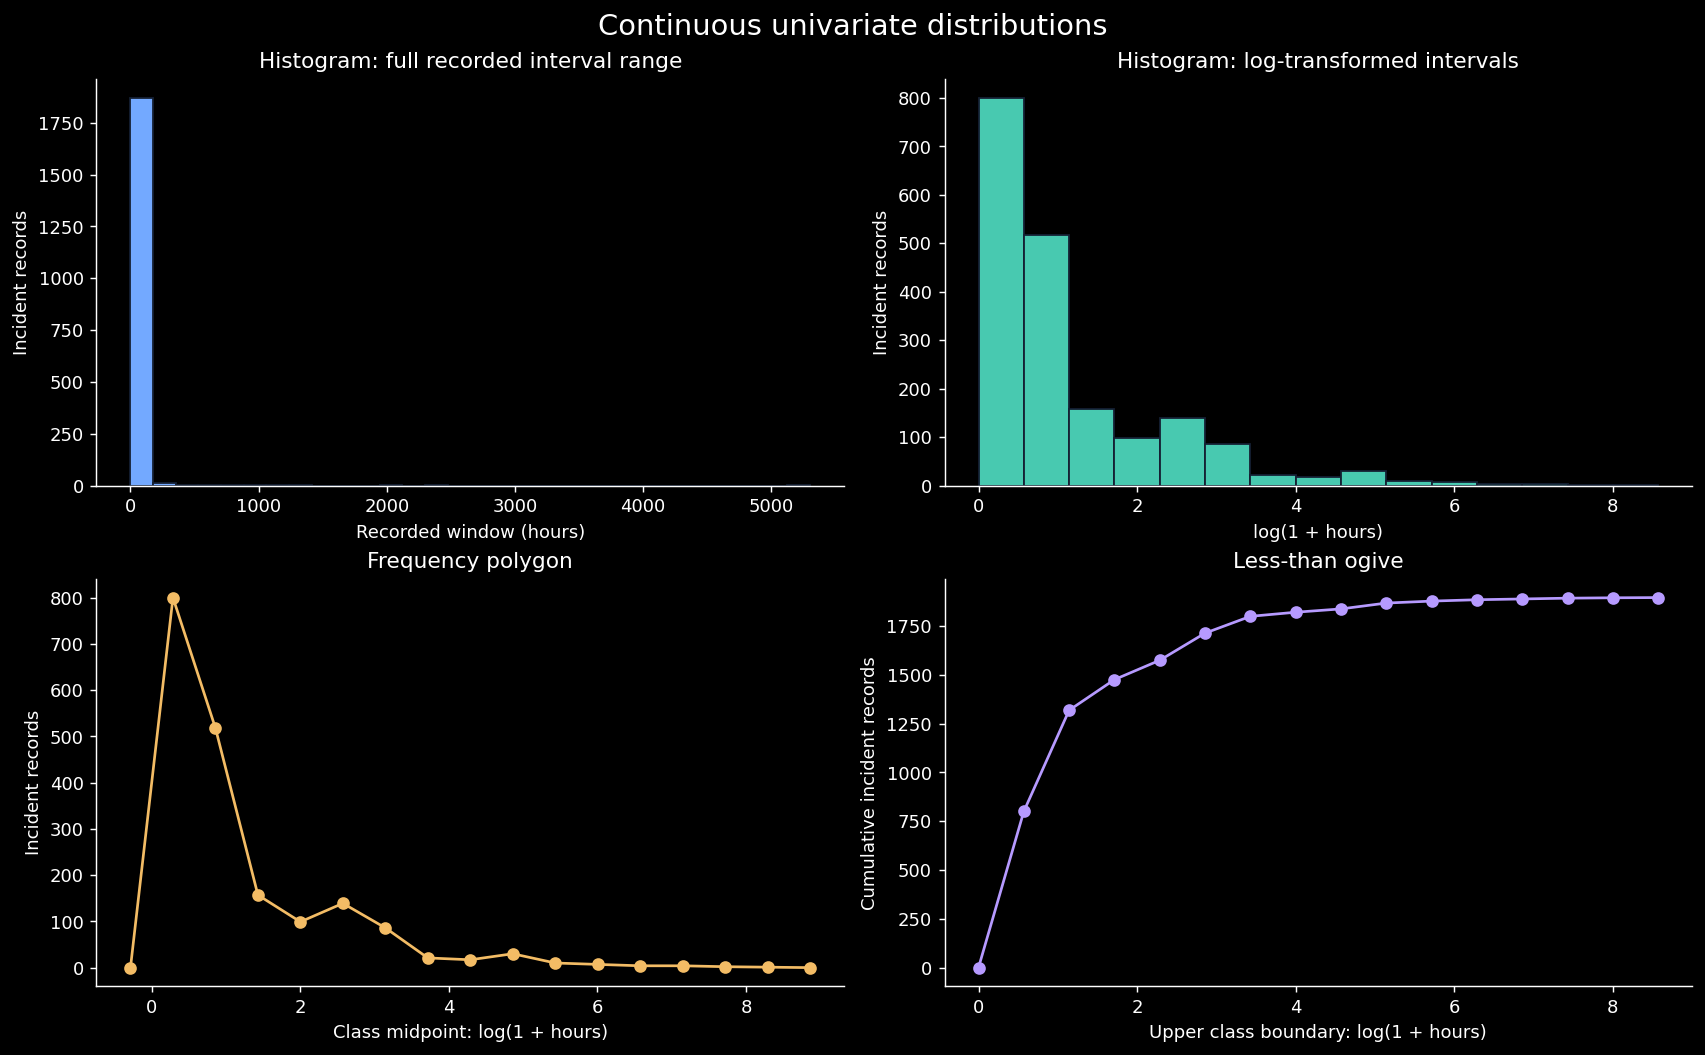

In [2]:
z = np.log1p(x)
frequency, edges = np.histogram(z, bins=15)
midpoints = (edges[:-1] + edges[1:]) / 2
class_width = edges[1] - edges[0]
cumulative = np.cumsum(frequency)

frequency_table = pd.DataFrame({
    "Lower log boundary": edges[:-1], "Upper log boundary": edges[1:],
    "Upper boundary in hours": np.expm1(edges[1:]),
    "Frequency": frequency, "Cumulative frequency": cumulative
})
display(frequency_table.round(3))

fig, axes = plt.subplots(2,2,figsize=(13,8),constrained_layout=True)
axes[0,0].hist(x, bins=30, color="#73a9ff", edgecolor="#152033")
axes[0,0].set(title="Histogram: full recorded interval range", xlabel="Recorded window (hours)", ylabel="Incident records")
axes[0,1].hist(z, bins=edges, color="#48c9b0", edgecolor="#152033")
axes[0,1].set(title="Histogram: log-transformed intervals", xlabel="log(1 + hours)", ylabel="Incident records")
polygon_x = np.r_[midpoints[0]-class_width, midpoints, midpoints[-1]+class_width]
polygon_y = np.r_[0, frequency, 0]
axes[1,0].plot(polygon_x, polygon_y, marker="o", color="#f3bc65")
axes[1,0].set(title="Frequency polygon", xlabel="Class midpoint: log(1 + hours)", ylabel="Incident records")
axes[1,1].plot(np.r_[edges[0],edges[1:]], np.r_[0,cumulative], marker="o", color="#b69aff")
axes[1,1].set(title="Less-than ogive", xlabel="Upper class boundary: log(1 + hours)", ylabel="Cumulative incident records")
fig.suptitle("Continuous univariate distributions", fontsize=16)
plt.show()
assert frequency.sum() == len(x)
assert cumulative[-1] == len(x)

**Reading these plots:** The original-hour histogram reveals the scale of extreme windows. The transformed plots expose variation near zero. The ogive must end at the number of valid intervals, not the total record count, because missing intervals are excluded.

### 4. Boxplots and outlier inspection
The first boxplot includes all outlier markers. The second hides markers to expose central spread without deleting any values. The grouped boxplot compares offenses on log(1+hours). Fences and flagged counts below are calculated on original hours, so they must not be confused with outliers recalculated on a transformed scale.

IQR-flagged windows: 348 of 1895 valid intervals
Flagged windows are retained for analysis.


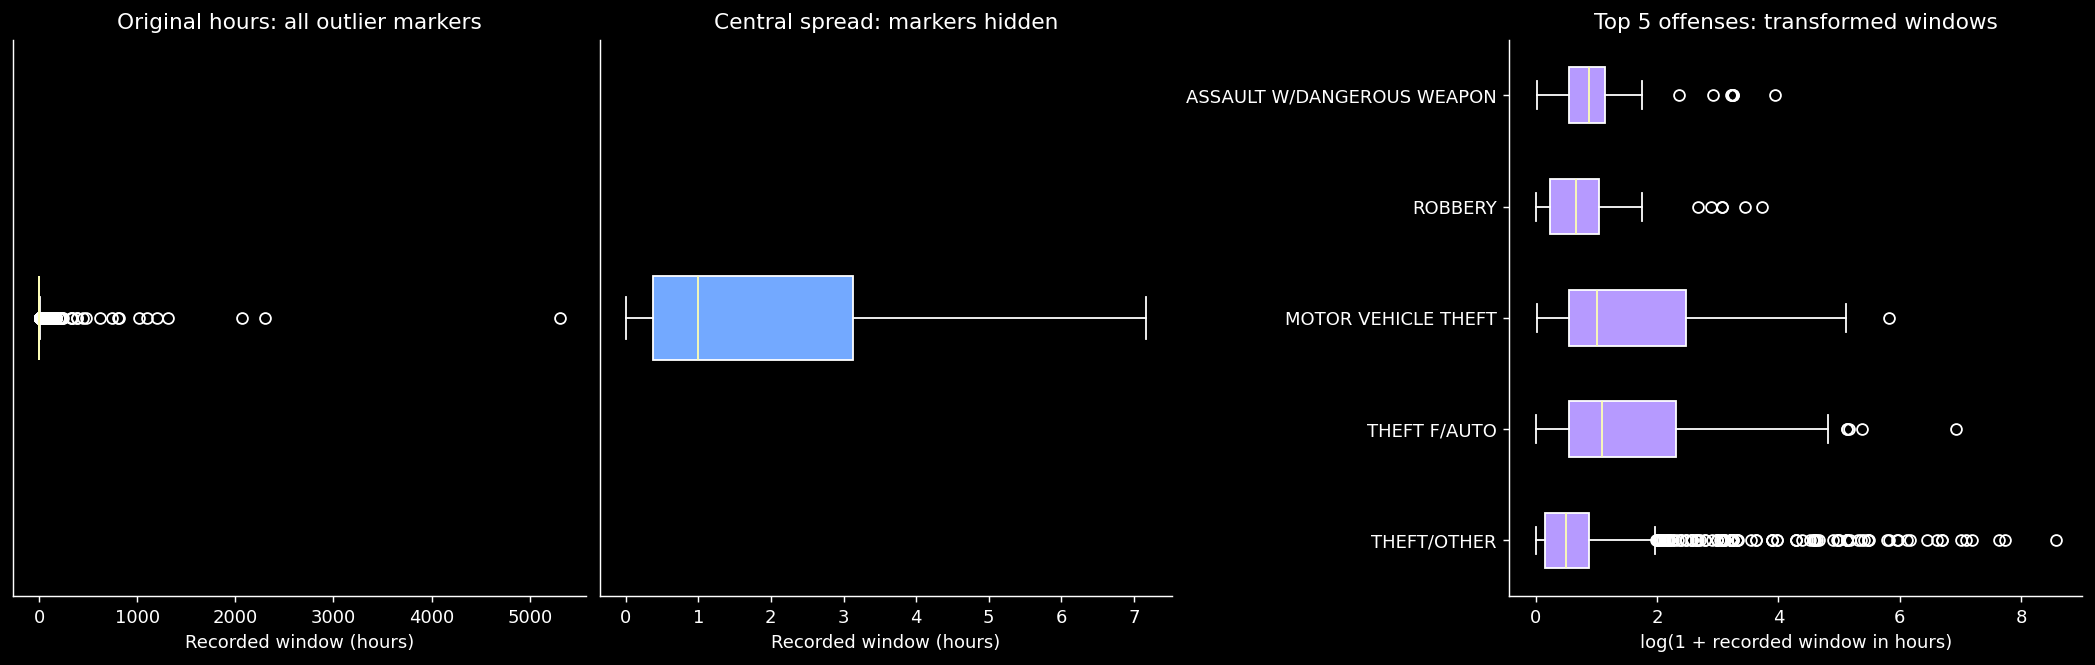

In [3]:
fig, axes = plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
axes[0].boxplot(x, vert=False, patch_artist=True, boxprops={"facecolor":"#48c9b0"})
axes[0].set(title="Original hours: all outlier markers", xlabel="Recorded window (hours)", yticks=[])
axes[1].boxplot(x, vert=False, showfliers=False, patch_artist=True, boxprops={"facecolor":"#73a9ff"})
axes[1].set(title="Central spread: markers hidden", xlabel="Recorded window (hours)", yticks=[])
offenses = df["OFFENSE"].value_counts().head(5).index
box_data = [np.log1p(df.loc[df["OFFENSE"] == name, "Recorded_Interval_Hours"].dropna()) for name in offenses]
axes[2].boxplot(box_data, vert=False, labels=offenses, patch_artist=True,
                boxprops={"facecolor":"#b69aff"})
axes[2].set(title="Top 5 offenses: transformed windows", xlabel="log(1 + recorded window in hours)")
plt.show()
print(f"IQR-flagged windows: {df['IQR_Flag'].sum()} of {len(x)} valid intervals")
print("Flagged windows are retained for analysis.")

### 5. Normal Q–Q plots
Q–Q plots visually assess normality; they do not prove it or replace a formal test. Points close to a straight reference line support an approximately normal shape. Curvature or large tail departures suggest otherwise. Compare original intervals with log(1+hours); a transformation does not guarantee normality.

Original intervals show a strong departure from a normal distribution.


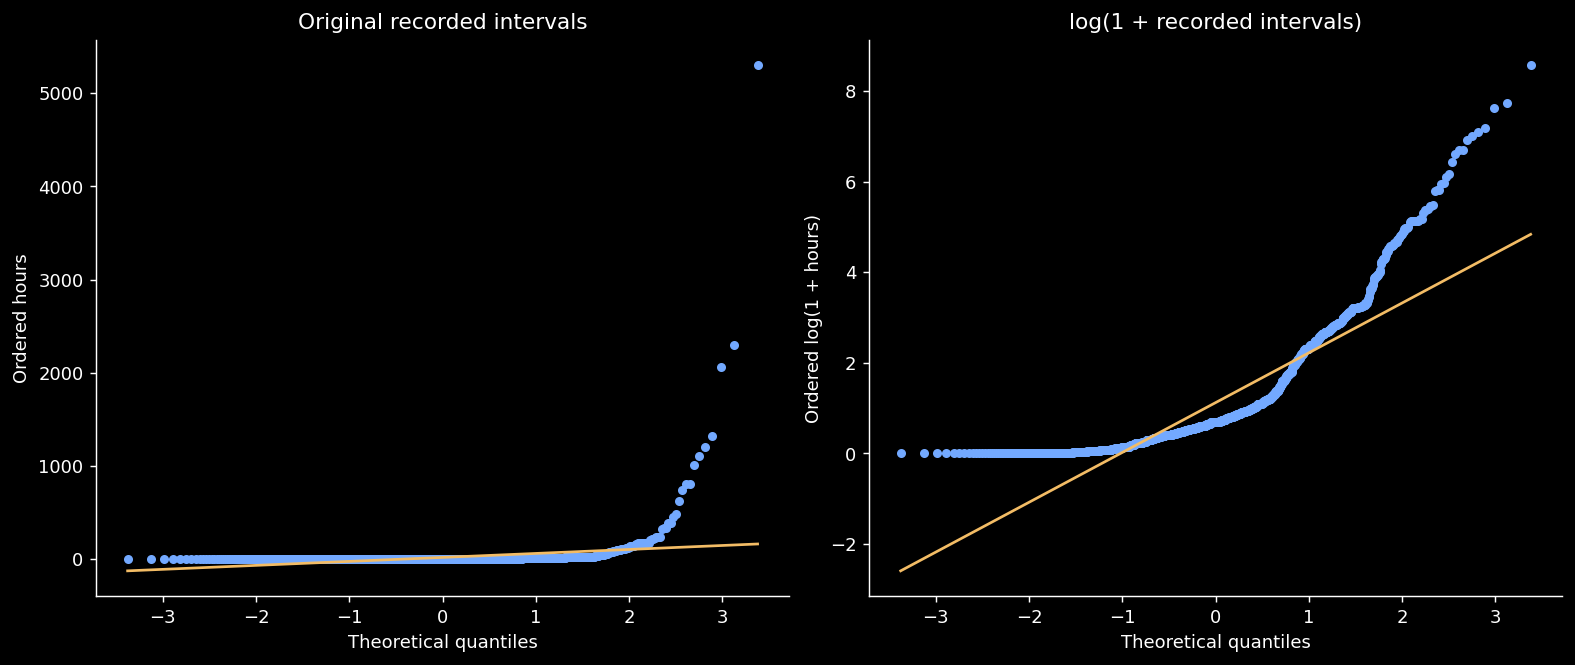

In [4]:
fig, axes = plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
for ax, values, title in [(axes[0], x, "Original recorded intervals"),
                           (axes[1], z, "log(1 + recorded intervals)")]:
    stats.probplot(values, dist="norm", plot=ax)
    ax.get_lines()[0].set(color="#73a9ff", markersize=4)
    ax.get_lines()[1].set(color="#f3bc65")
    ax.set_title(title)
axes[0].set_ylabel("Ordered hours")
axes[1].set_ylabel("Ordered log(1 + hours)")
plt.show()
print("Original intervals show a strong departure from a normal distribution.")

### 6. Daily data for relational analysis
Use counts per UTC report date. Include zero-count days between the minimum and maximum observed dates. Boundary dates may be partial. Theft counts combine categories containing THEFT, assault counts use categories containing ASSAULT, and robbery counts use ROBBERY. The three categories are disjoint. Correlations use these daily counts, not category codes or IDs.

In [5]:
df["Report_Day_UTC"] = df["REPORT_DAT"].dt.floor("D")
days = pd.date_range(df["Report_Day_UTC"].min(), df["Report_Day_UTC"].max(), freq="D")
daily = pd.DataFrame(index=days)
daily["All reports"] = df.groupby("Report_Day_UTC").size().reindex(days, fill_value=0)
for name, pattern in [("Theft reports", "THEFT"), ("Assault reports", "ASSAULT"), ("Robbery reports", "ROBBERY")]:
    selected = df[df["OFFENSE"].str.contains(pattern, case=False, na=False)]
    daily[name] = selected.groupby("Report_Day_UTC").size().reindex(days, fill_value=0)
display(daily.head())
print("Number of report dates:", len(daily))
assert daily["All reports"].sum() == df["REPORT_DAT"].notna().sum()

Number of report dates: 30


,All reports,Theft reports,Assault reports,Robbery reports
2026-09-23 00:00:00+00:00,67,63,3,1
2026-09-24 00:00:00+00:00,89,70,11,5
2026-09-25 00:00:00+00:00,70,61,1,5
2026-09-26 00:00:00+00:00,86,72,4,6
2026-09-27 00:00:00+00:00,50,42,3,3


### 7. Scatter plots
The first plot explores whether theft and robbery report counts rise together by date. Each dot is one UTC report date. The second plots incident coordinates; repeated/overlapping block positions may hide records. It shows spatial distribution, not road distance or population-adjusted risk.

Pearson correlation, daily theft vs robbery: 0.11


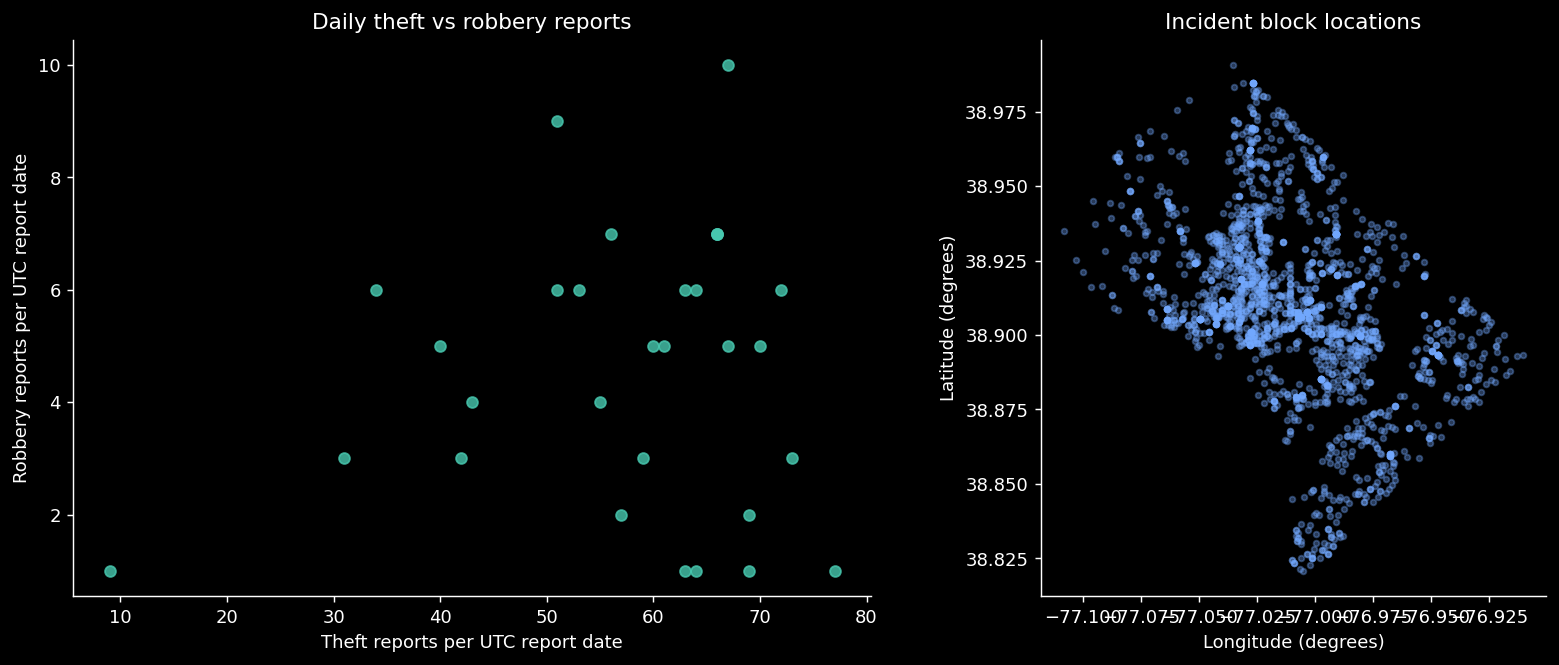

In [6]:
fig, axes = plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
axes[0].scatter(daily["Theft reports"], daily["Robbery reports"], color="#48c9b0", alpha=0.8)
axes[0].set(title="Daily theft vs robbery reports", xlabel="Theft reports per UTC report date", ylabel="Robbery reports per UTC report date")
axes[1].scatter(df["LONGITUDE"], df["LATITUDE"], s=10, alpha=0.35, color="#73a9ff")
axes[1].set(title="Incident block locations", xlabel="Longitude (degrees)", ylabel="Latitude (degrees)")
axes[1].set_aspect(1 / np.cos(np.deg2rad(df["LATITUDE"].mean())))
plt.show()
print("Pearson correlation, daily theft vs robbery:", round(daily["Theft reports"].corr(daily["Robbery reports"]), 3))

### 8. Pair-plot and correlation matrix
A pair-plot is a scatterplot matrix: off-diagonal panels compare each pair, and diagonal panels show distributions. pandas scatter_matrix creates it without an extra plotting library. Only three offense-count features are used to keep the figure readable. Short reporting windows, partial days and shared reporting conditions limit interpretation; correlation does not show causality.

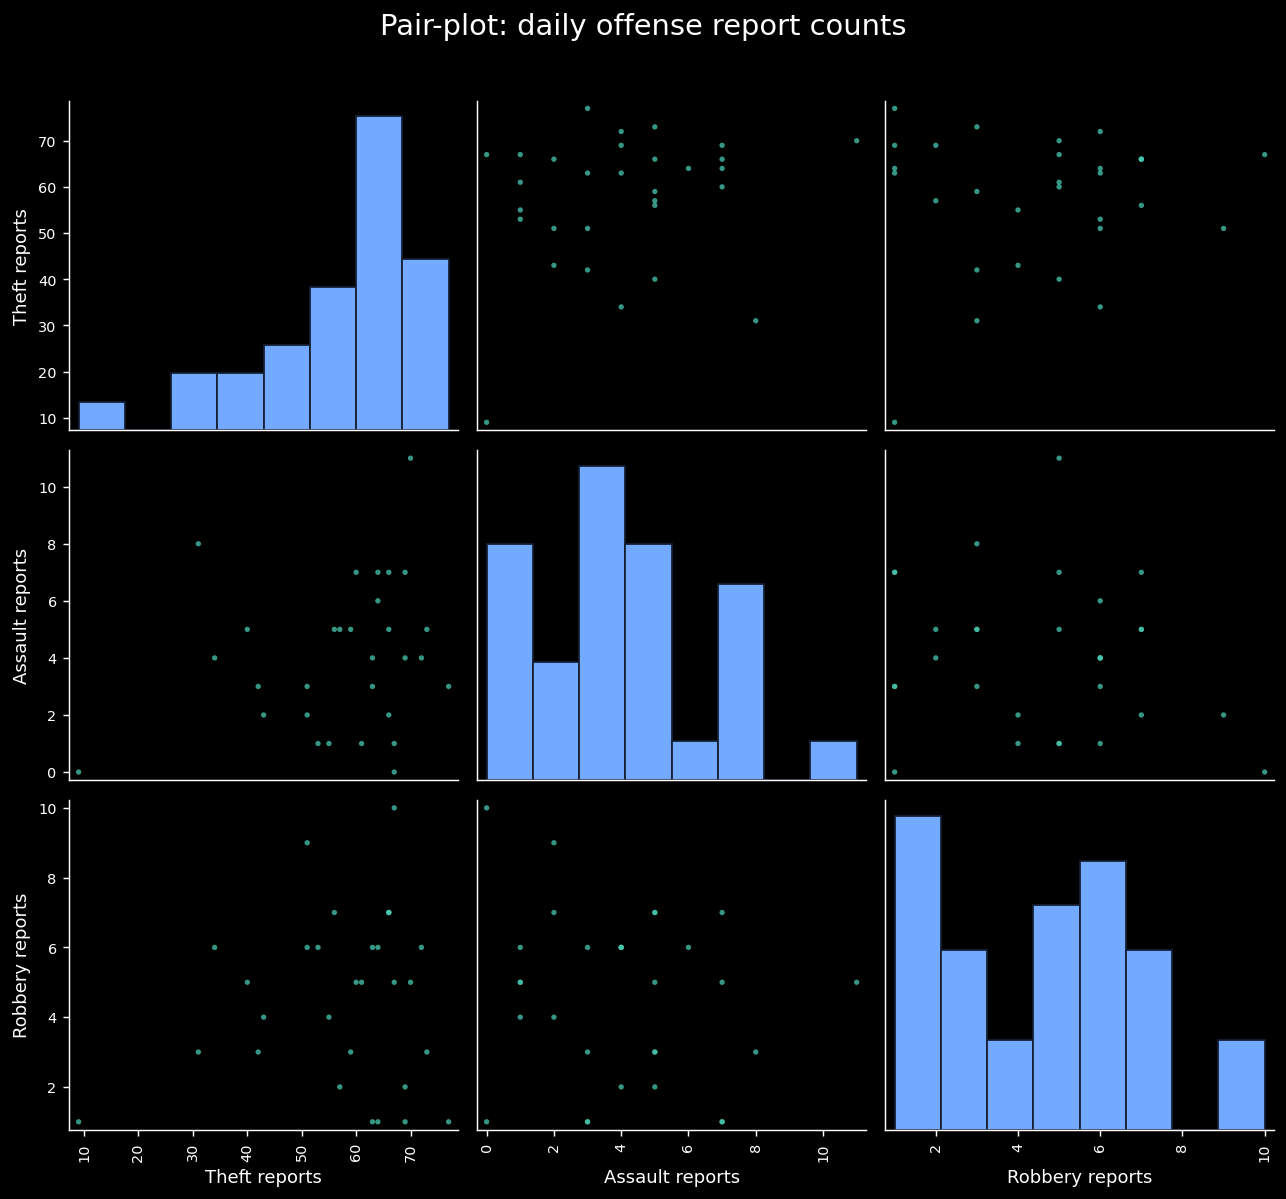

,Theft reports,Assault reports,Robbery reports
Theft reports,1.000,0.224,0.110
Assault reports,0.224,1.000,-0.172
Robbery reports,0.110,-0.172,1.000


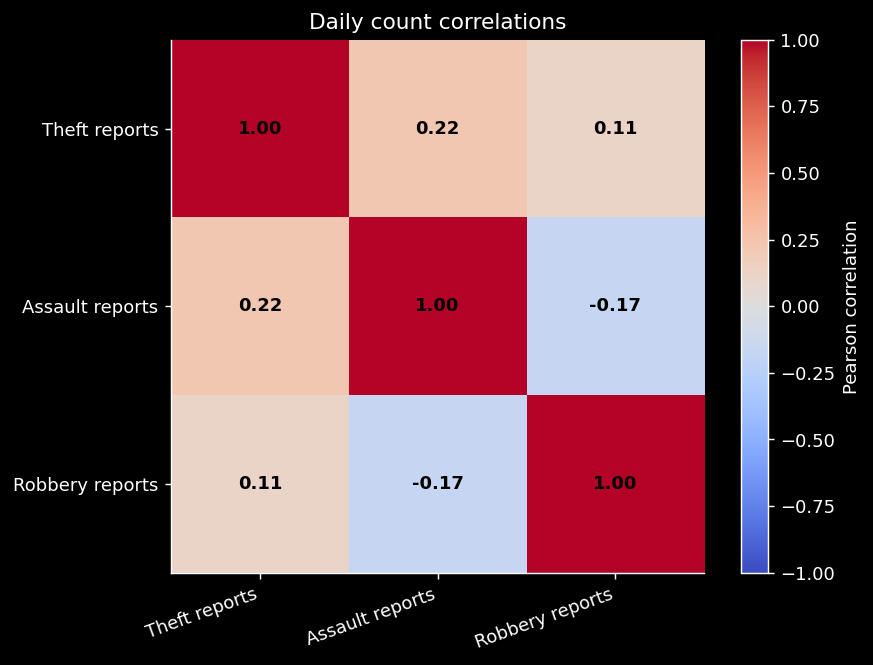

In [7]:
pair_data = daily[["Theft reports", "Assault reports", "Robbery reports"]]
axes = scatter_matrix(pair_data, figsize=(10,9), diagonal="hist",
                      color="#48c9b0", alpha=0.75, s=35,
                      hist_kwds={"bins":8,"color":"#73a9ff","edgecolor":"#152033"})
for ax in axes.ravel():
    ax.tick_params(axis="both", labelsize=8)
plt.suptitle("Pair-plot: daily offense report counts", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

correlation = pair_data.corr()
display(correlation.round(3))
fig, ax = plt.subplots(figsize=(7,5),constrained_layout=True)
heatmap = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(3), correlation.columns, rotation=20, ha="right")
ax.set_yticks(range(3), correlation.index)
for i in range(3):
    for j in range(3):
        ax.text(j,i,f"{correlation.iloc[i,j]:.2f}",ha="center",va="center",color="black",weight="bold")
fig.colorbar(heatmap,ax=ax,label="Pearson correlation")
ax.set_title("Daily count correlations")
plt.show()

### 9. Scoreboard and dashboard preview
A scoreboard presents headline KPIs. A dashboard adds visual detail and exploration. The static preview below is saved for immediate viewing. The next cell adds offense, shift and ward filters, refreshed KPIs, selectable daily/shift/method bars, and a record table. Median and IQR flags use available intervals; the IQR fences remain fixed from the full dataset so filtered groups stay comparable.

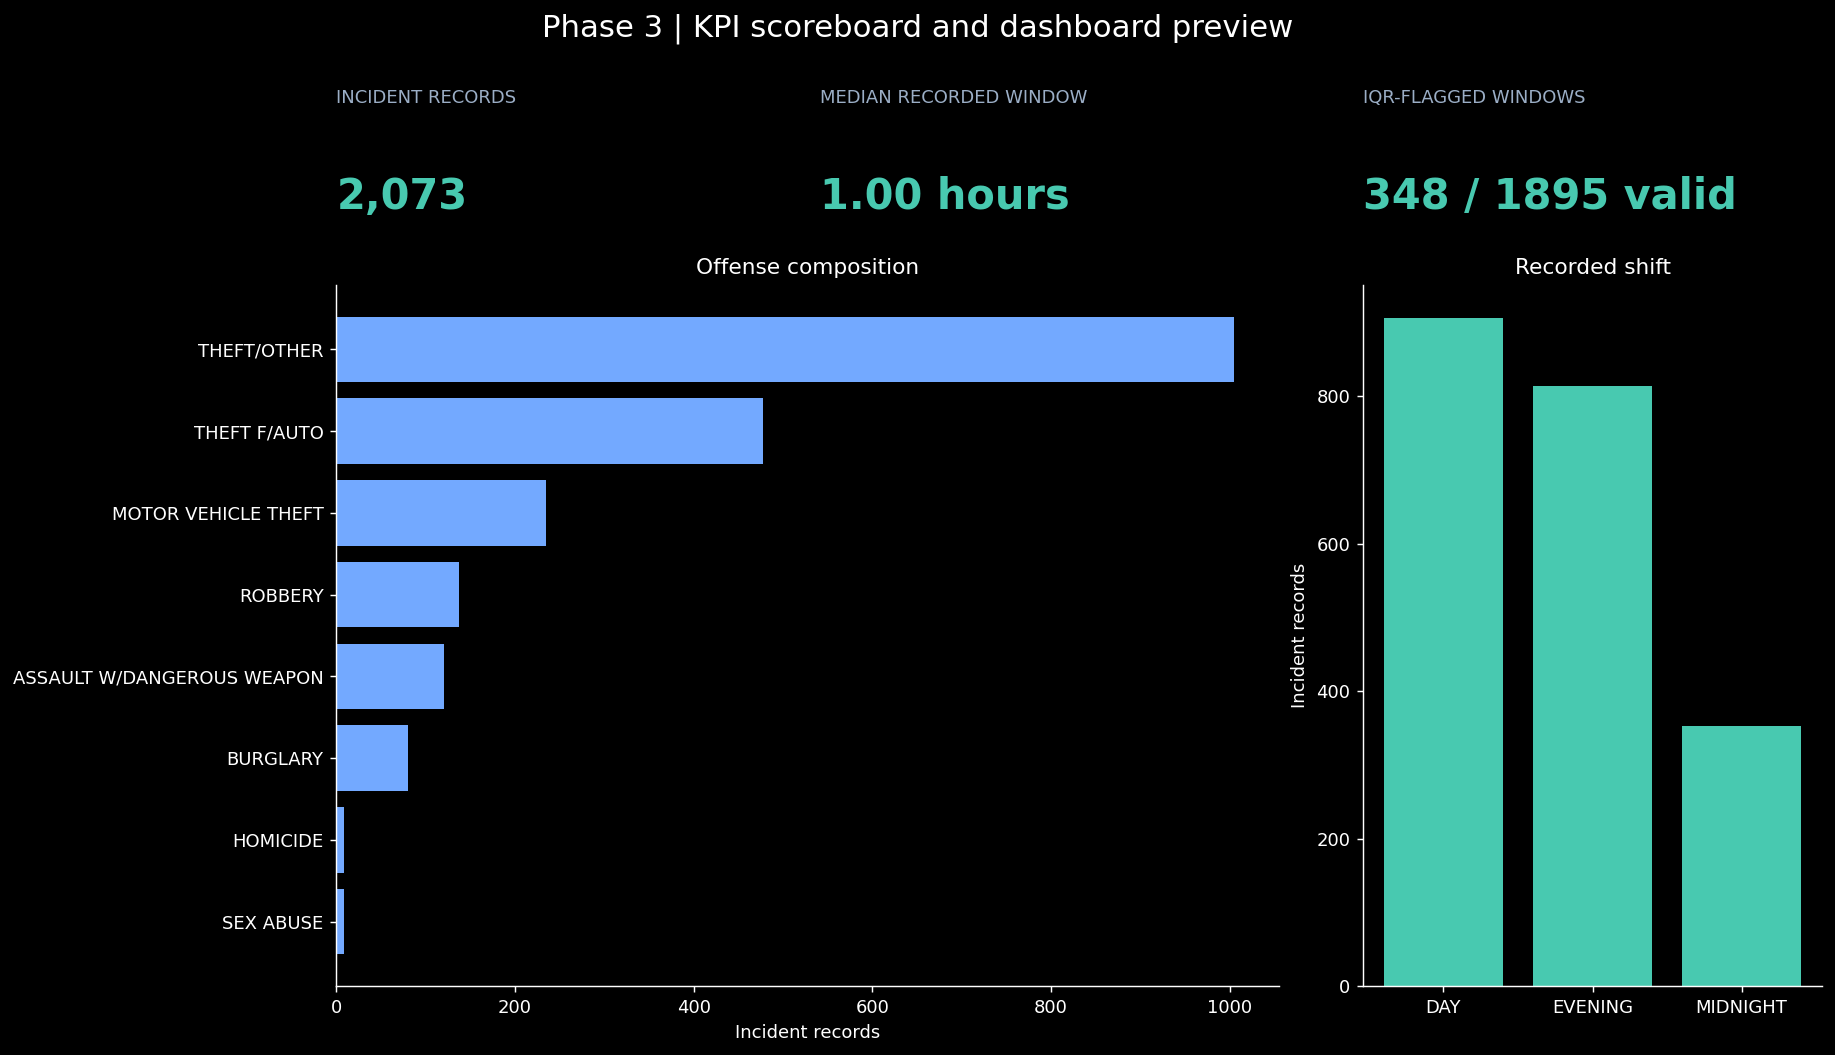

In [8]:
fig = plt.figure(figsize=(14,8),constrained_layout=True)
grid = fig.add_gridspec(2,3,height_ratios=[0.55,2])
kpis = [("INCIDENT RECORDS", f"{len(df):,}"), ("MEDIAN RECORDED WINDOW", f"{x.median():.2f} hours"),
        ("IQR-FLAGGED WINDOWS", f"{df['IQR_Flag'].sum()} / {len(x)} valid")]
for i,(label,value) in enumerate(kpis):
    ax=fig.add_subplot(grid[0,i]); ax.axis("off")
    ax.text(0,0.75,label,color="#9baec6",fontsize=10)
    ax.text(0,0.2,value,color="#48c9b0",fontsize=23,weight="bold")
ax=fig.add_subplot(grid[1,:2])
counts=df["OFFENSE"].value_counts().sort_values()
ax.barh(counts.index,counts.values,color="#73a9ff")
ax.set(title="Offense composition",xlabel="Incident records")
ax=fig.add_subplot(grid[1,2])
counts=df["SHIFT"].value_counts()
ax.bar(counts.index,counts.values,color="#48c9b0")
ax.set(title="Recorded shift",ylabel="Incident records")
fig.suptitle("Phase 3 | KPI scoreboard and dashboard preview",fontsize=17)
plt.show()

### 10. Interactive dashboard with drill-down
**Run this cell to activate.** Select an offense, shift and ward; choose a breakdown. KPI cards, bars and the record table update together. Click a bar to drill into that group; click **Clear bar selection** to return. The table shows the first 20 matching records and states how many remain.

The dashboard is self-contained HTML/JavaScript and needs no external chart service. If a saved output is blocked, rerun this cell in Colab. All date grouping shown here uses UTC report dates. Selected bars change the KPIs as well as the table. No predictive risk score is calculated.

In [9]:
# A small HTML wrapper lets display() render the dashboard.
class DashboardHTML:
    def __init__(self, html):
        self.html = html
    def _repr_html_(self):
        return self.html

dashboard_data = pd.DataFrame({
    "id": df["CCN"].astype(str), "offense": df["OFFENSE"],
    "shift": df["SHIFT"], "ward": df["WARD"], "method": df["METHOD"],
    "day": df["REPORT_DAT"].dt.strftime("%Y-%m-%d"),
    "hours": df["Recorded_Interval_Hours"], "flag": df["IQR_Flag"],
    "block": df["BLOCK"]
})
data_json = dashboard_data.to_json(orient="records").replace("<", "\u003c")

html = """
<div id="crime-dashboard" style="font:14px Arial;background:#101827;color:#edf3ff;padding:22px;border-radius:12px">
<h2 style="margin-top:0">Crime incidents | Interactive dashboard</h2>
<p>Filter the records, then click a bar for a detailed view.</p>
<div style="display:flex;gap:15px;flex-wrap:wrap">
<label>Offense <select id="offense"></select></label>
<label>Shift <select id="shift"></select></label>
<label>Ward <select id="ward"></select></label>
<label>Breakdown <select id="breakdown"><option value="offense">Offense</option><option value="shift">Shift</option><option value="method">Method</option><option value="day">Report date (UTC)</option></select></label>
<button id="clear">Clear bar selection</button></div>
<div id="cards" style="display:flex;gap:15px;flex-wrap:wrap;margin:22px 0"></div>
<p id="selection"></p><div id="bars"></div>
<h3>Matching incident records</h3><p id="table-note"></p>
<div style="overflow:auto"><table id="records" style="width:100%;border-collapse:collapse;text-align:left"></table></div>
<p style="color:#a9bad2">Recorded windows may reflect uncertainty about occurrence times. Missing intervals are excluded from median and outlier denominators. IQR flags use the full-data fences. Counts are records, not population-adjusted risk.</p>
</div>
<script>
(()=>{
const data=__DATA__;
const root=document.getElementById('crime-dashboard');
const el=id=>root.querySelector('#'+id);
let selected=null;
const escape=s=>String(s??'Unknown').replace(/[&<>"']/g,c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[c]));
for(const key of ['offense','shift','ward']){
  const values=[...new Set(data.map(r=>r[key]))].sort();
  el(key).innerHTML='<option value="">All</option>'+values.map(v=>'<option>'+escape(v)+'</option>').join('');
  el(key).onchange=()=>{selected=null;render();};
}
el('breakdown').onchange=()=>{selected=null;render();};
el('clear').onclick=()=>{selected=null;render();};
function render(){
  const filtered=data.filter(r=>['offense','shift','ward'].every(k=>!el(k).value||r[k]===el(k).value));
  const key=el('breakdown').value;
  const groups={};
  filtered.forEach(r=>{const value=r[key]??'Unknown';groups[value]=(groups[value]||0)+1;});
  const rows=selected===null?filtered:filtered.filter(r=>(r[key]??'Unknown')===selected);
  const hours=rows.map(r=>r.hours).filter(v=>v!==null&&Number.isFinite(v)).sort((a,b)=>a-b);
  const n=hours.length;
  const median=n?(n%2?hours[(n-1)/2]:(hours[n/2-1]+hours[n/2])/2).toFixed(2)+' h':'Not available';
  const flagged=rows.filter(r=>r.flag&&r.hours!==null).length;
  const cards=[['Incident records',rows.length.toLocaleString()],['Median recorded window',median],['IQR-flagged windows',flagged+' / '+n+' valid']];
  el('cards').innerHTML=cards.map(([a,b])=>'<div style="background:#1c2940;padding:18px;min-width:180px;border-radius:8px"><div>'+a+'</div><strong style="font-size:25px;color:#58dcc1">'+b+'</strong></div>').join('');
  el('selection').textContent=selected===null?'All groups in selected filters. Click a bar to drill down.':'Bar selection: '+selected+' — KPIs and table show this group.';
  const entries=Object.entries(groups).sort(key==='day'?(a,b)=>a[0].localeCompare(b[0]):(a,b)=>b[1]-a[1]);
  const maximum=Math.max(1,...entries.map(e=>e[1]));
  el('bars').innerHTML=entries.length?'':'No matching records. Change a filter.';
  entries.forEach(([name,total])=>{
    const button=document.createElement('button');
    button.style.cssText='display:block;width:100%;text-align:left;background:transparent;color:#edf3ff;border:0;padding:6px;cursor:pointer';
    button.innerHTML='<span style="display:inline-block;width:235px;max-width:60%">'+escape(name)+'</span><span style="display:inline-block;background:'+(selected===name?'#f3bc65':'#48c9b0')+';height:16px;width:'+Math.max(1,total/maximum*48)+'%"></span> '+total;
    button.onclick=()=>{selected=selected===name?null:name;render();};
    el('bars').appendChild(button);
  });
  const keys=['id','day','offense','shift','ward','hours','block'];
  el('records').innerHTML='<tr>'+keys.map(k=>'<th style="padding:8px;border-bottom:1px solid #536079">'+k+'</th>').join('')+'</tr>'+rows.slice(0,20).map(r=>'<tr>'+keys.map(k=>'<td style="padding:8px;border-bottom:1px solid #293951">'+escape(k==='hours'?(r.hours===null?'Missing':r.hours.toFixed(2)):r[k])+'</td>').join('')+'</tr>').join('');
  el('table-note').textContent='Showing '+Math.min(20,rows.length)+' of '+rows.length+' matching records. '+Math.max(0,rows.length-20)+' additional records are not displayed.';
}
render();
})();
</script>
"""
html = html.replace("__DATA__", data_json)
display(DashboardHTML(html))
print("Dashboard ready: change filters or click bars to explore the records.")

Dashboard ready: change filters or click bars to explore the records.


### 11. Interpretation and presentation notes
- Explain the units and transformation before interpreting each plot. Most recorded windows are short relative to the longest windows.
- Use original-hour IQR fences to identify records for review, not automatic deletion.
- Q–Q plots show a substantial departure from normality in original hours.
- The pair-plot explores daily category-count relationships over this reporting window; correlation does not explain causes.
- Use dashboard filters to compare subsets and the table to inspect individual records. Small subsets may give unstable summaries.
- Reporting date, occurrence window and recorded shift are distinct attributes. Boundary report dates may be incomplete.

### Phase 3 completion checklist
| Requirement | Included |
|---|---|
| Histogram | Original and log-transformed windows |
| Frequency polygon | Shared transformed class boundaries |
| Ogive | Less-than cumulative frequency curve |
| Boxplots | Full range, central spread and offense comparison |
| Q–Q plots | Original and transformed windows |
| Scatter plots | Daily offense counts and spatial coordinates |
| Pair-plot | Three daily offense-count attributes |
| Scoreboard | Three clearly defined KPIs |
| Interactive dashboard | Offense/shift/ward filters, breakdown selection, clickable bars, updated KPIs and record table |

**Sources:** Supplied crime CSV; supplied FDS Mini Competition Guidelines and rubric. No external data or causal claims are introduced.